In [2]:
import pandas as pd
df=pd.read_csv("auto_mpg.csv")
print(df)

      mpg  cylinders  displacement  horsepower  weight  acceleration  \
0    18.0          8         307.0       130.0    3504          12.0   
1    15.0          8         350.0       165.0    3693          11.5   
2    18.0          8         318.0       150.0    3436          11.0   
3    16.0          8         304.0       150.0    3433          12.0   
4    17.0          8         302.0       140.0    3449          10.5   
..    ...        ...           ...         ...     ...           ...   
393  27.0          4         140.0        86.0    2790          15.6   
394  44.0          4          97.0        52.0    2130          24.6   
395  32.0          4         135.0        84.0    2295          11.6   
396  28.0          4         120.0        79.0    2625          18.6   
397  31.0          4         119.0        82.0    2720          19.4   

     model_year  origin                       name  
0            70     usa  chevrolet chevelle malibu  
1            70     usa      

In [3]:
df.drop('name',axis=1,inplace=True)
print(df.columns)

Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model_year', 'origin'],
      dtype='object')


In [4]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['origin']=le.fit_transform(df['origin'])
print(df)

      mpg  cylinders  displacement  horsepower  weight  acceleration  \
0    18.0          8         307.0       130.0    3504          12.0   
1    15.0          8         350.0       165.0    3693          11.5   
2    18.0          8         318.0       150.0    3436          11.0   
3    16.0          8         304.0       150.0    3433          12.0   
4    17.0          8         302.0       140.0    3449          10.5   
..    ...        ...           ...         ...     ...           ...   
393  27.0          4         140.0        86.0    2790          15.6   
394  44.0          4          97.0        52.0    2130          24.6   
395  32.0          4         135.0        84.0    2295          11.6   
396  28.0          4         120.0        79.0    2625          18.6   
397  31.0          4         119.0        82.0    2720          19.4   

     model_year  origin  
0            70       2  
1            70       2  
2            70       2  
3            70       2  
4    

In [5]:
print(df['origin'].unique())

[2 1 0]


In [6]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [7]:
df.fillna(method='ffill',inplace=True)
df.isnull().sum()

C:\Users\HP\AppData\Local\Temp\ipykernel_14208\627222060.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill',inplace=True)


mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [8]:
x=df.iloc[:,1:8]
y=df[['mpg']]
print(x)


     cylinders  displacement  horsepower  weight  acceleration  model_year  \
0            8         307.0       130.0    3504          12.0          70   
1            8         350.0       165.0    3693          11.5          70   
2            8         318.0       150.0    3436          11.0          70   
3            8         304.0       150.0    3433          12.0          70   
4            8         302.0       140.0    3449          10.5          70   
..         ...           ...         ...     ...           ...         ...   
393          4         140.0        86.0    2790          15.6          82   
394          4          97.0        52.0    2130          24.6          82   
395          4         135.0        84.0    2295          11.6          82   
396          4         120.0        79.0    2625          18.6          82   
397          4         119.0        82.0    2720          19.4          82   

     origin  
0         2  
1         2  
2         2  
3      

In [9]:
print(y)

      mpg
0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
..    ...
393  27.0
394  44.0
395  32.0
396  28.0
397  31.0

[398 rows x 1 columns]


In [10]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)
print('Training set size:',x_train.shape[0])
print('Testing set size:',x_test.shape[0])

Training set size: 318
Testing set size: 80


In [11]:
x_train

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
320,4,119.0,92.0,2434,15.0,80,1
6,8,454.0,220.0,4354,9.0,70,2
110,4,108.0,94.0,2379,16.5,73,1
217,4,111.0,80.0,2155,14.8,77,2
229,8,400.0,180.0,4220,11.1,77,2
...,...,...,...,...,...,...,...
87,8,350.0,145.0,3988,13.0,73,2
46,4,140.0,72.0,2408,19.0,71,2
349,4,91.0,68.0,1985,16.0,81,1
224,8,302.0,130.0,4295,14.9,77,2


In [12]:
x_test

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
364,8,350.0,105.0,3725,19.0,81,2
169,6,232.0,100.0,2914,16.0,75,2
150,4,108.0,93.0,2391,15.5,74,1
143,4,97.0,78.0,2300,14.5,74,0
306,6,173.0,115.0,2595,11.3,79,2
...,...,...,...,...,...,...,...
117,4,68.0,49.0,1867,19.5,73,0
386,6,181.0,110.0,2945,16.4,82,2
202,6,258.0,95.0,3193,17.8,76,2
221,8,305.0,145.0,3880,12.5,77,2


In [13]:
y_train

,mpg
320,37.0
6,14.0
110,22.0
217,30.0
229,16.0
...,...
87,13.0
46,22.0
349,34.1
224,15.0


In [14]:
y_test

,mpg
364,26.6
169,20.0
150,26.0
143,26.0
306,28.8
...,...
117,29.0
386,25.0
202,17.5
221,17.5


In [15]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(x_train, y_train)

y_pred = lr.predict(x_test)

print("Predicted MPG values:")
print(y_pred)


Predicted MPG values:
[[23.58174078]
 [22.76806206]
 [25.68710824]
 [27.52698075]
 [26.40335046]
 [10.37785726]
 [25.37719088]
 [27.01760306]
 [27.6704466 ]
 [31.44302935]
 [14.98139732]
 [18.94644783]
 [33.97959767]
 [10.11139157]
 [ 8.39041032]
 [10.50027401]
 [18.71074688]
 [26.374107  ]
 [25.90622754]
 [29.00543548]
 [24.14698569]
 [22.03919767]
 [13.49045571]
 [30.96317565]
 [28.304477  ]
 [32.21062989]
 [30.7406918 ]
 [27.38046346]
 [20.72924011]
 [29.47154269]
 [14.83159743]
 [14.57634361]
 [25.92068767]
 [21.96734715]
 [24.99854462]
 [31.23138801]
 [12.04552147]
 [31.81463496]
 [17.39197725]
 [28.03123037]
 [29.78364042]
 [13.8319413 ]
 [28.41437554]
 [20.72452611]
 [24.63365422]
 [28.5533294 ]
 [22.8641631 ]
 [19.25752998]
 [29.68041327]
 [28.32483133]
 [15.28763999]
 [16.76983191]
 [29.17056062]
 [33.74909423]
 [27.93646602]
 [23.56394799]
 [23.99295988]
 [12.68959812]
 [14.00562895]
 [25.10413308]
 [23.26288285]
 [24.57176034]
 [31.42965762]
 [25.68496116]
 [20.68031973]
 [1

In [16]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print("Mean squared error:",mse)
print("Mean absoulate error:",mae)
print("R_squared score:",r2)

Mean squared error: 12.005915100589098
Mean absoulate error: 2.6459932937670727
R_squared score: 0.7746238280712848


In [17]:
import numpy as np
rmse=np.sqrt(mse)
print(rmse)

3.464955281181721


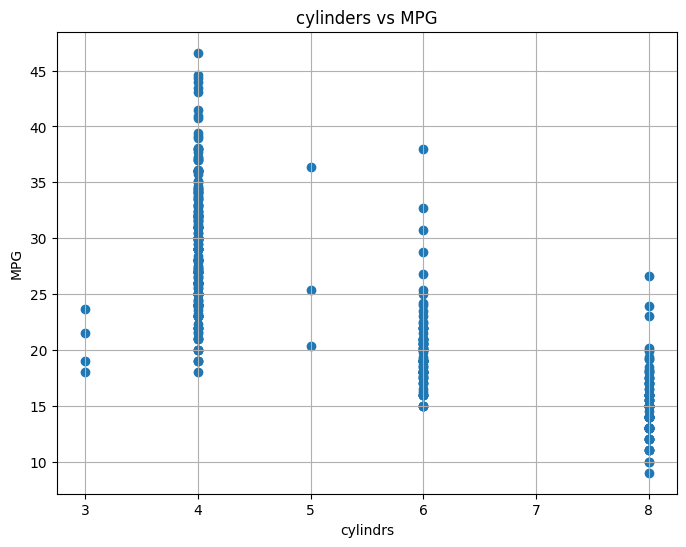

In [18]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(x['cylinders'],y)
plt.title("cylinders vs MPG")
plt.xlabel('cylindrs')
plt.ylabel('MPG')
plt.grid(True)
plt.show()